# Профиль исходной таблицы Wine Quality (White Wine)

Анализ до какой-либо предобработки. Данные НИКАК не изменяются.

Перед запуском загрузить winequality-white.csv через панель Files слева.

Запуск: Runtime - Run all.

In [1]:
import os
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'DejaVu Sans'
print('OK: libraries loaded')

OK: libraries loaded


In [2]:
CSV_NAME = 'winequality-white.csv'

if not os.path.exists(CSV_NAME):
    raise FileNotFoundError(
        'Файл winequality-white.csv не найден. '
        'Загрузите его через панель Files слева (иконка папки - Upload).'
    )

df = pd.read_csv(CSV_NAME, sep=';')
print('OK: dataset loaded')
print('Rows:', df.shape[0])
print('Cols:', df.shape[1])

OK: dataset loaded
Rows: 4898
Cols: 12


## 1. Общая информация

In [3]:
print('=' * 70)
print('GENERAL INFO')
print('=' * 70)

buf = io.StringIO()
df.info(buf=buf)
print(buf.getvalue())

print()
mem_mb = round(df.memory_usage(deep=True).sum() / 1024 / 1024, 3)
print('Memory usage (MB):', mem_mb)
print()
print('Dtypes:')
print(df.dtypes.to_string())
print()
print('Shape:', df.shape)

GENERAL INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


Memory usage (MB): 0.449

Dtypes:
fixed acidity           float64
volatile acidity        float64
citric acid  

## 2. Первые, последние и случайные строки

In [4]:
print('HEAD (5 rows):')
print(df.head().to_string())

print()
print('TAIL (5 rows):')
print(df.tail().to_string())

print()
print('RANDOM SAMPLE (5 rows):')
print(df.sample(5, random_state=42).to_string())

HEAD (5 rows):
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  alcohol  quality
0            7.0              0.27         0.36            20.7      0.045                 45.0                 170.0   1.0010  3.00       0.45      8.8        6
1            6.3              0.30         0.34             1.6      0.049                 14.0                 132.0   0.9940  3.30       0.49      9.5        6
2            8.1              0.28         0.40             6.9      0.050                 30.0                  97.0   0.9951  3.26       0.44     10.1        6
3            7.2              0.23         0.32             8.5      0.058                 47.0                 186.0   0.9956  3.19       0.40      9.9        6
4            7.2              0.23         0.32             8.5      0.058                 47.0                 186.0   0.9956  3.19       0.40      9.9        6

TAIL (5 rows

## 3. Характеристика признаков

### 3.1. Определение смысла, типа и правила для каждого поля

In [5]:
feature_spec = [
    {'field': 'fixed acidity',
     'meaning': 'Фиксированная кислотность',
     'dtype': 'Число (float)',
     'rule': '> 0'},
    {'field': 'volatile acidity',
     'meaning': 'Летучая кислотность',
     'dtype': 'Число (float)',
     'rule': '>= 0'},
    {'field': 'citric acid',
     'meaning': 'Лимонная кислота',
     'dtype': 'Число (float)',
     'rule': '>= 0'},
    {'field': 'residual sugar',
     'meaning': 'Остаточный сахар',
     'dtype': 'Число (float)',
     'rule': '>= 0'},
    {'field': 'chlorides',
     'meaning': 'Хлориды (соль)',
     'dtype': 'Число (float)',
     'rule': '> 0'},
    {'field': 'free sulfur dioxide',
     'meaning': 'Свободный SO2',
     'dtype': 'Число (float)',
     'rule': '>= 0'},
    {'field': 'total sulfur dioxide',
     'meaning': 'Общий SO2',
     'dtype': 'Число (float)',
     'rule': '>= free sulfur dioxide'},
    {'field': 'density',
     'meaning': 'Плотность',
     'dtype': 'Число (float)',
     'rule': '0.98 - 1.05'},
    {'field': 'pH',
     'meaning': 'Кислотность среды',
     'dtype': 'Число (float)',
     'rule': '0 - 14'},
    {'field': 'sulphates',
     'meaning': 'Сульфаты',
     'dtype': 'Число (float)',
     'rule': '>= 0'},
    {'field': 'alcohol',
     'meaning': 'Содержание алкоголя, %',
     'dtype': 'Число (float)',
     'rule': '> 0, обычно 8 - 15'},
    {'field': 'quality',
     'meaning': 'Оценка качества',
     'dtype': 'Целое число',
     'rule': '3 - 9, целевая переменная'}
]

spec_df = pd.DataFrame(feature_spec)
print('Характеристика признаков:')
print(spec_df.to_string(index=False))

Характеристика признаков:
               field                   meaning         dtype                      rule
       fixed acidity Фиксированная кислотность Число (float)                       > 0
    volatile acidity       Летучая кислотность Число (float)                      >= 0
         citric acid          Лимонная кислота Число (float)                      >= 0
      residual sugar          Остаточный сахар Число (float)                      >= 0
           chlorides            Хлориды (соль) Число (float)                       > 0
 free sulfur dioxide             Свободный SO2 Число (float)                      >= 0
total sulfur dioxide                 Общий SO2 Число (float)    >= free sulfur dioxide
             density                 Плотность Число (float)               0.98 - 1.05
                  pH         Кислотность среды Число (float)                    0 - 14
           sulphates                  Сульфаты Число (float)                      >= 0
             alco

### 3.2. Практика: профиль таблицы

Проверки по правилам из 3.1:
- **Пропуски** — от всего датасета
- **Неверный формат** — от непустых значений
- **Вне диапазона** — от числовых значений

In [6]:
N = len(df)

def fmt_pct(x, base):
    if base == 0:
        return 'n/a'
    return str(round(x / base * 100, 2)) + '%'

checks = []

# 1. Пропуски по каждому полю
for col in df.columns:
    n_miss = int(df[col].isnull().sum())
    checks.append({
        'check': 'Пропуски: ' + col,
        'violations': n_miss,
        'base': N,
        'share': fmt_pct(n_miss, N)
    })

# 2. Неверный формат: там где ожидается число, а получилось не число
# Проверяем через попытку привести к float
for col in df.columns:
    coerced = pd.to_numeric(df[col], errors='coerce')
    non_empty = df[col].notnull().sum()
    n_bad_fmt = int((df[col].notnull() & coerced.isnull()).sum())
    if n_bad_fmt > 0:
        checks.append({
            'check': 'Неверный формат: ' + col,
            'violations': n_bad_fmt,
            'base': non_empty,
            'share': fmt_pct(n_bad_fmt, non_empty)
        })

# 3. Проверки диапазонов для ключевых полей
range_rules = [
    ('fixed acidity', 'fixed acidity <= 0', lambda s: s <= 0),
    ('volatile acidity', 'volatile acidity < 0', lambda s: s < 0),
    ('citric acid', 'citric acid < 0', lambda s: s < 0),
    ('residual sugar', 'residual sugar < 0', lambda s: s < 0),
    ('chlorides', 'chlorides <= 0', lambda s: s <= 0),
    ('free sulfur dioxide', 'free SO2 < 0', lambda s: s < 0),
    ('total sulfur dioxide', 'total SO2 < 0', lambda s: s < 0),
    ('density', 'density вне 0.98 - 1.05', lambda s: (s < 0.98) | (s > 1.05)),
    ('pH', 'pH вне 0 - 14', lambda s: (s < 0) | (s > 14)),
    ('sulphates', 'sulphates < 0', lambda s: s < 0),
    ('alcohol', 'alcohol <= 0', lambda s: s <= 0),
    ('quality', 'quality вне 3 - 9', lambda s: (s < 3) | (s > 9)),
]

for col, label, rule in range_rules:
    s = pd.to_numeric(df[col], errors='coerce')
    numeric_base = int(s.notnull().sum())
    mask = rule(s.fillna(0)) & s.notnull()
    n_bad = int(mask.sum())
    checks.append({
        'check': 'Диапазон: ' + label,
        'violations': n_bad,
        'base': numeric_base,
        'share': fmt_pct(n_bad, numeric_base)
    })

# 4. Логическая проверка: total SO2 >= free SO2
free_s = pd.to_numeric(df['free sulfur dioxide'], errors='coerce')
total_s = pd.to_numeric(df['total sulfur dioxide'], errors='coerce')
both = free_s.notnull() & total_s.notnull()
n_logic = int((both & (total_s < free_s)).sum())
checks.append({
    'check': 'Логика: total SO2 < free SO2',
    'violations': n_logic,
    'base': int(both.sum()),
    'share': fmt_pct(n_logic, int(both.sum()))
})

checks_df = pd.DataFrame(checks)
checks_df = checks_df[['check', 'violations', 'base', 'share']]

print('Профиль проверок (Пропуски / Неверный формат / Диапазон / Логика):')
print()
print(checks_df.to_string(index=False))

total_violations = int(checks_df['violations'].sum())
print()
print('Всего нарушений по всем проверкам:', total_violations)

Профиль проверок (Пропуски / Неверный формат / Диапазон / Логика):

                            check  violations  base share
          Пропуски: fixed acidity           0  4898  0.0%
       Пропуски: volatile acidity           0  4898  0.0%
            Пропуски: citric acid           0  4898  0.0%
         Пропуски: residual sugar           0  4898  0.0%
              Пропуски: chlorides           0  4898  0.0%
    Пропуски: free sulfur dioxide           0  4898  0.0%
   Пропуски: total sulfur dioxide           0  4898  0.0%
                Пропуски: density           0  4898  0.0%
                     Пропуски: pH           0  4898  0.0%
              Пропуски: sulphates           0  4898  0.0%
                Пропуски: alcohol           0  4898  0.0%
                Пропуски: quality           0  4898  0.0%
     Диапазон: fixed acidity <= 0           0  4898  0.0%
   Диапазон: volatile acidity < 0           0  4898  0.0%
        Диапазон: citric acid < 0           0  4898  0.0%
    

### 3.3. Только нарушения (без нулей)

In [7]:
viol = checks_df[checks_df['violations'] > 0].reset_index(drop=True)

if viol.shape[0] == 0:
    print('Нарушений по всем правилам нет.')
else:
    print('Нарушения, требующие внимания:')
    print()
    print(viol.to_string(index=False))
    print()
    print('Число проверок с нарушениями:', viol.shape[0])
    print('Суммарно нарушений:', int(viol['violations'].sum()))

Нарушений по всем правилам нет.


## 4. Профиль по каждому столбцу

In [8]:
profile = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notnull().sum(),
    'null': df.isnull().sum(),
    'null_pct': (df.isnull().sum() / len(df) * 100).round(2),
    'unique': df.nunique(),
    'min': df.min(numeric_only=True),
    'q25': df.quantile(0.25, numeric_only=True),
    'median': df.median(numeric_only=True),
    'q75': df.quantile(0.75, numeric_only=True),
    'max': df.max(numeric_only=True),
    'mean': df.mean(numeric_only=True).round(3),
    'std': df.std(numeric_only=True).round(3),
    'skew': df.skew(numeric_only=True).round(3),
    'kurtosis': df.kurtosis(numeric_only=True).round(3)
})

cols_order = ['dtype', 'non_null', 'null', 'null_pct', 'unique',
              'min', 'q25', 'median', 'q75', 'max',
              'mean', 'std', 'skew', 'kurtosis']
profile = profile[cols_order]

print('=' * 70)
print('COLUMN PROFILE')
print('=' * 70)
print(profile.to_string())

COLUMN PROFILE
                        dtype  non_null  null  null_pct  unique      min         q25     median       q75        max     mean     std   skew  kurtosis
fixed acidity         float64      4898     0       0.0      68  3.80000    6.300000    6.80000    7.3000   14.20000    6.855   0.844  0.648     2.172
volatile acidity      float64      4898     0       0.0     125  0.08000    0.210000    0.26000    0.3200    1.10000    0.278   0.101  1.577     5.092
citric acid           float64      4898     0       0.0      87  0.00000    0.270000    0.32000    0.3900    1.66000    0.334   0.121  1.282     6.175
residual sugar        float64      4898     0       0.0     310  0.60000    1.700000    5.20000    9.9000   65.80000    6.391   5.072  1.077     3.470
chlorides             float64      4898     0       0.0     160  0.00900    0.036000    0.04300    0.0500    0.34600    0.046   0.022  5.023    37.565
free sulfur dioxide   float64      4898     0       0.0     132  2.00000   23.0

## 5. Пропуски (без изменений)

In [9]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'missing': missing,
    'missing_pct': missing_pct
}).sort_values('missing', ascending=False)

print('Total missing cells:', int(missing.sum()))
print('Columns with missing values:')
sub = missing_df[missing_df['missing'] > 0]
if sub.shape[0] == 0:
    print('  none')
else:
    print(sub.to_string())

Total missing cells: 0
Columns with missing values:
  none


## 6. Дубликаты (без удаления)

In [10]:
n_dups = int(df.duplicated().sum())
share = round(n_dups / len(df) * 100, 2)

print('Duplicated rows (full match):', n_dups)
print('Share of duplicates (%):', share)
print('Unique rows:', df.drop_duplicates().shape[0])

if n_dups > 0:
    print()
    print('Top-5 most frequent rows:')
    vc = df.value_counts().head(5).reset_index(name='count')
    print(vc.to_string())

Duplicated rows (full match): 937
Share of duplicates (%): 19.13
Unique rows: 3961

Top-5 most frequent rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  alcohol  quality  count
0            7.3              0.19         0.27            13.9      0.057                 45.0                 155.0  0.99807  2.94       0.41      8.8        8      8
1            7.0              0.15         0.28            14.7      0.051                 29.0                 149.0  0.99792  2.96       0.39      9.0        7      8
2            6.8              0.18         0.30            12.8      0.062                 19.0                 171.0  0.99808  3.00       0.52      9.0        7      7
3            7.4              0.16         0.30            13.7      0.056                 33.0                 168.0  0.99825  2.90       0.44      8.7        7      7
4            7.4              0.19         0.

## 7. Константные и почти константные признаки

In [11]:
nunique = df.nunique().sort_values()
print('Unique values per column (ascending):')
print(nunique.to_string())

const_cols = list(nunique[nunique == 1].index)
low_var = list(nunique[nunique <= 5].index)

print()
print('Constant columns:', const_cols if const_cols else 'none')
print('Columns with <=5 unique values:', low_var if low_var else 'none')

Unique values per column (ascending):
quality                   7
fixed acidity            68
sulphates                79
citric acid              87
alcohol                 103
pH                      103
volatile acidity        125
free sulfur dioxide     132
chlorides               160
total sulfur dioxide    251
residual sugar          310
density                 890

Constant columns: none
Columns with <=5 unique values: none


## 8. Баланс классов

In [12]:
counts = df['quality'].value_counts().sort_index()
pcts = (counts / len(df) * 100).round(2)

balance = pd.DataFrame({
    'count': counts,
    'pct': pcts
})
print('Class distribution for quality:')
print(balance.to_string())

print()
print('Number of classes:', counts.shape[0])
print('Min class size:', counts.min())
print('Max class size:', counts.max())
print('Imbalance ratio (max/min):', round(counts.max() / counts.min(), 2))

Class distribution for quality:
         count    pct
quality              
3           20   0.41
4          163   3.33
5         1457  29.75
6         2198  44.88
7          880  17.97
8          175   3.57
9            5   0.10

Number of classes: 7
Min class size: 5
Max class size: 2198
Imbalance ratio (max/min): 439.6


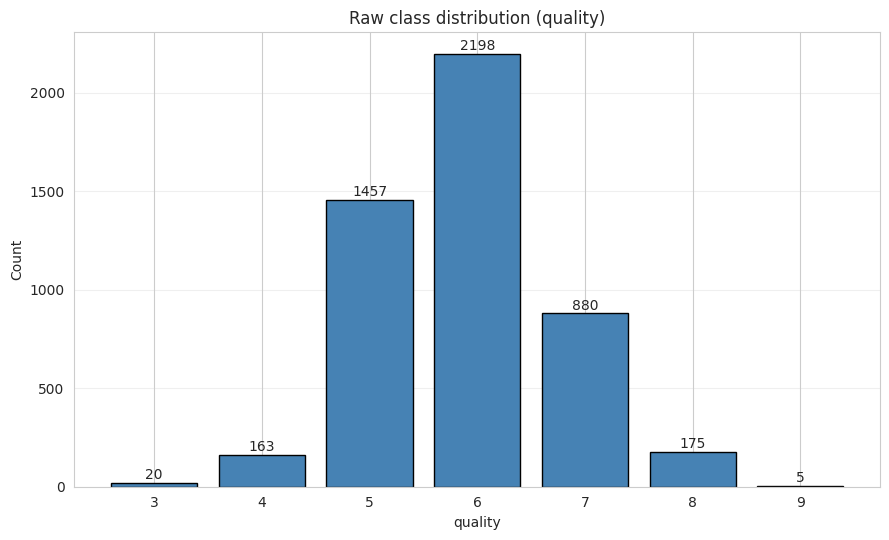

In [13]:
fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(counts.index.astype(str), counts.values,
              color='steelblue', edgecolor='black')
ax.set_title('Raw class distribution (quality)')
ax.set_xlabel('quality')
ax.set_ylabel('Count')
ax.grid(alpha=0.3, axis='y')
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 20,
            str(v), ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('raw_class_bar.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Распределения всех числовых признаков

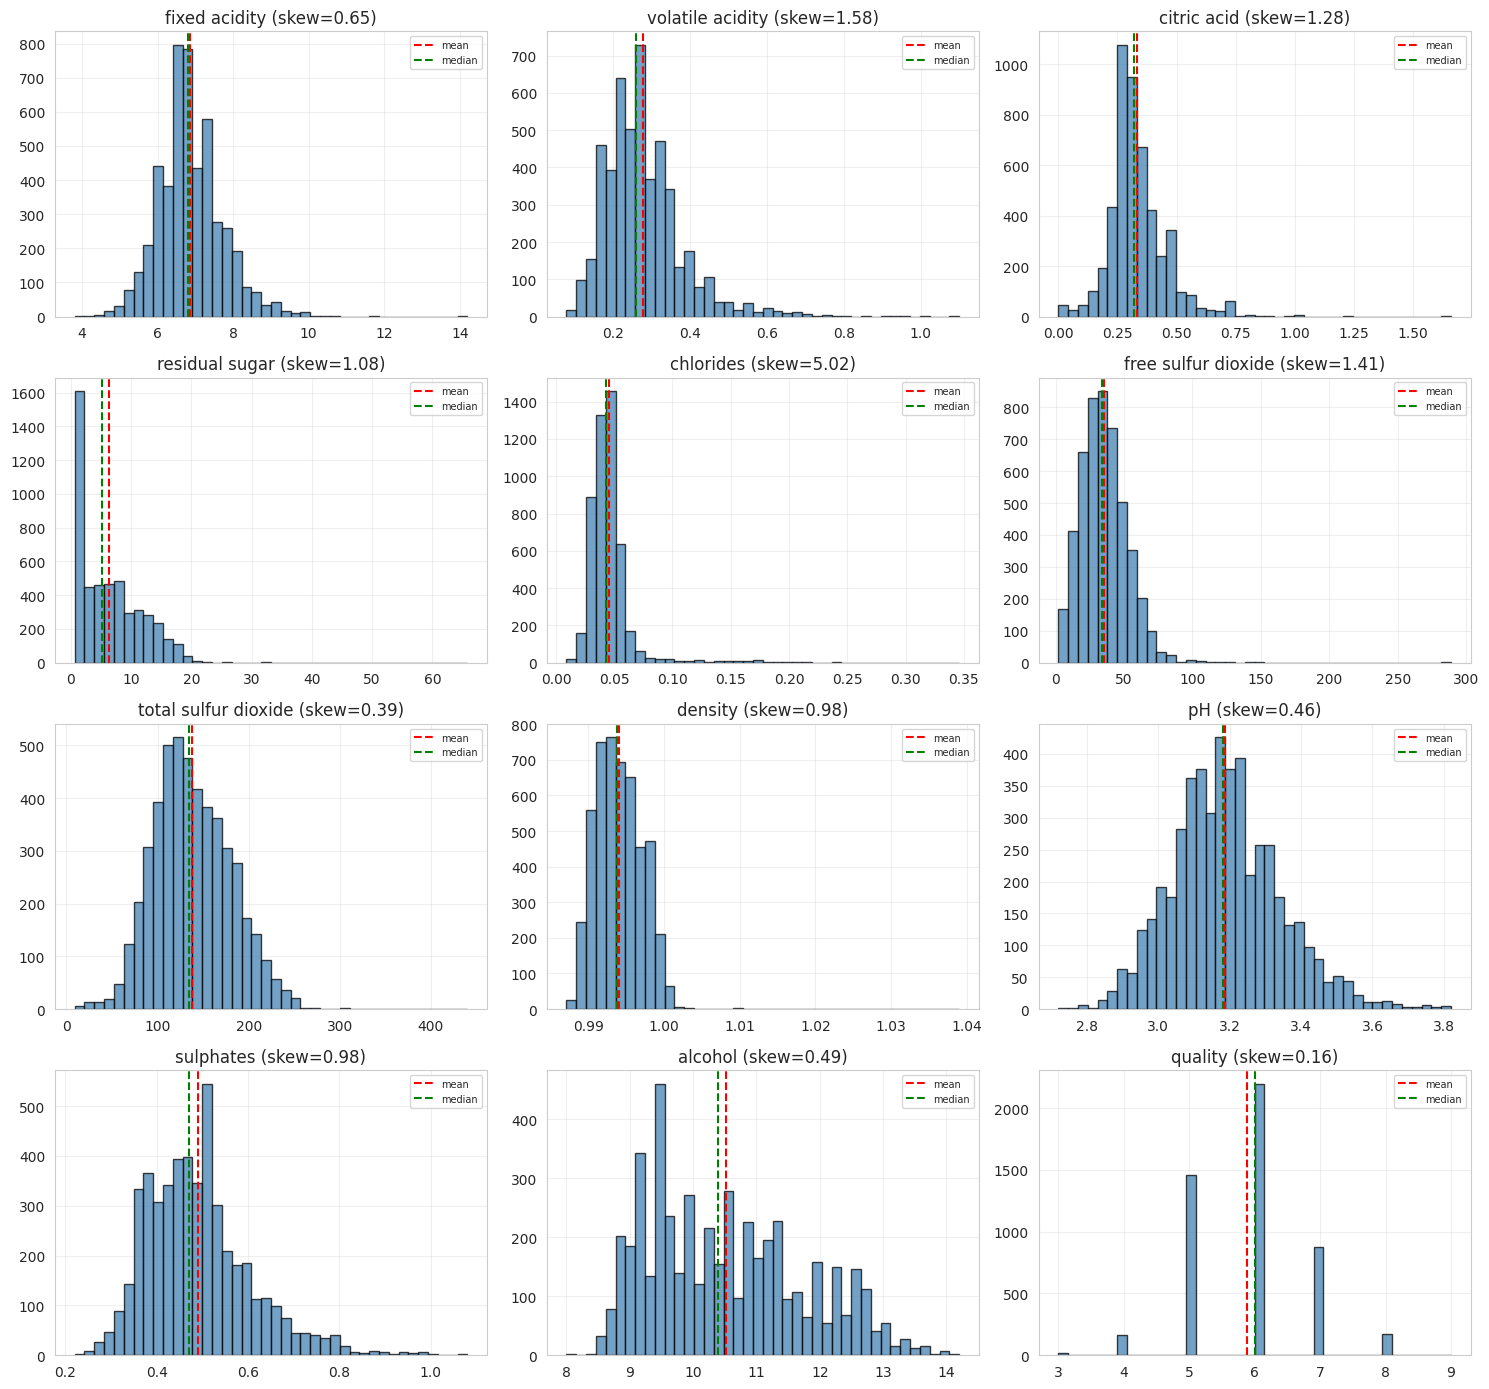

In [14]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=40, color='steelblue',
                 edgecolor='black', alpha=0.75)
    axes[i].axvline(df[col].mean(), color='red',
                    linestyle='--', label='mean')
    axes[i].axvline(df[col].median(), color='green',
                    linestyle='--', label='median')
    sk = round(df[col].skew(), 2)
    axes[i].set_title(col + ' (skew=' + str(sk) + ')')
    axes[i].legend(fontsize=7)
    axes[i].grid(alpha=0.3)

for j in range(len(numeric_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('raw_distributions.png', dpi=100, bbox_inches='tight')
plt.show()

## 10. Boxplot для приоритетных признаков

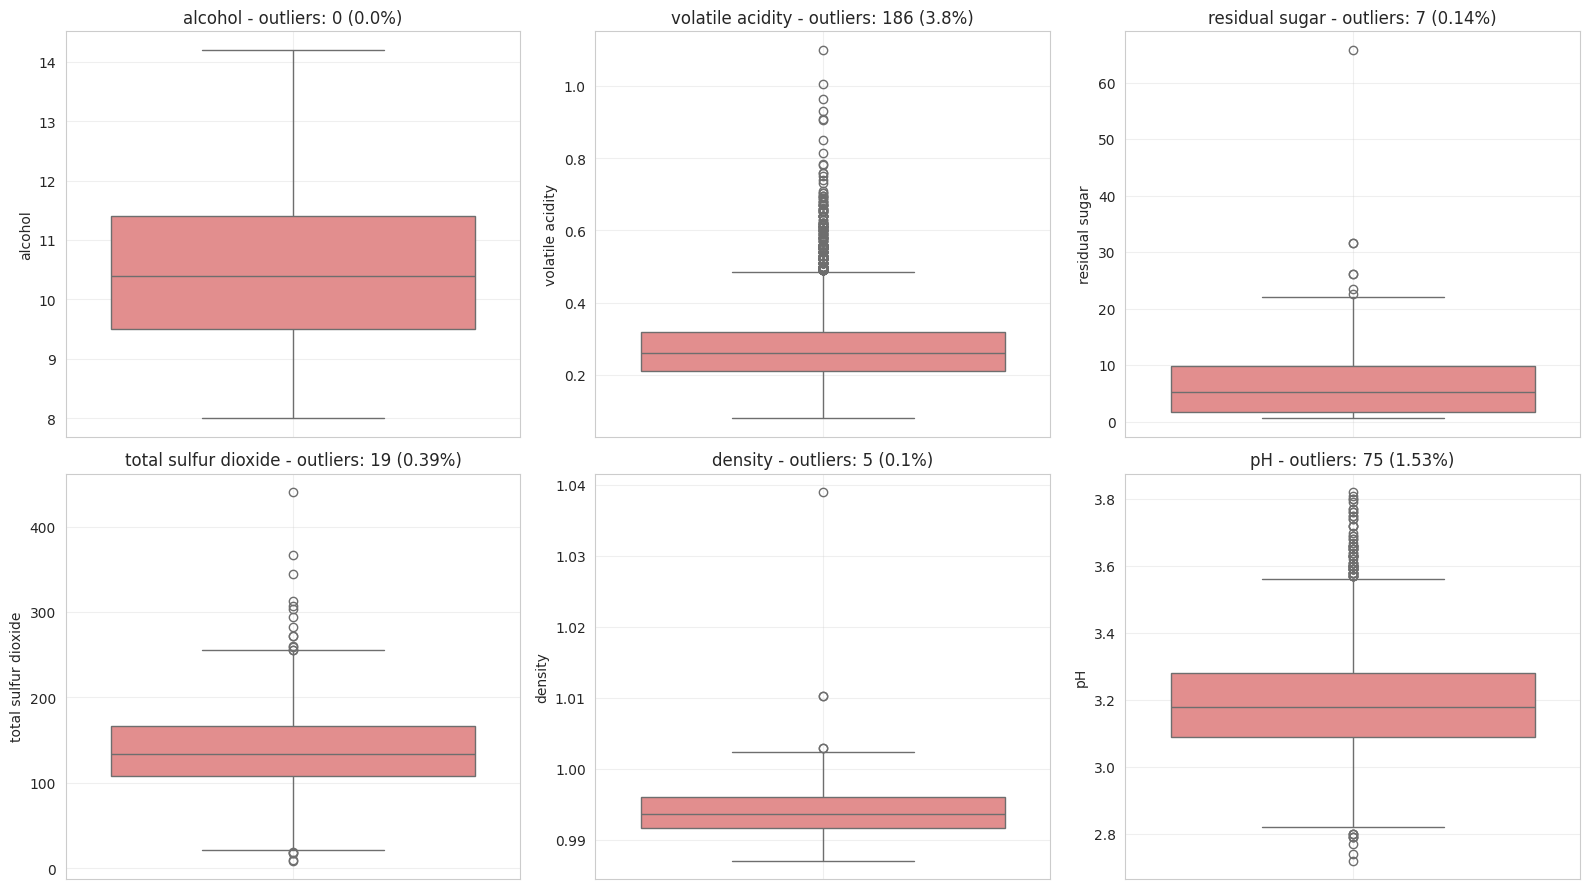

Outlier report (IQR rule):
                      n_outliers   pct   lower    upper
alcohol                      0.0  0.00   6.650   14.250
volatile acidity           186.0  3.80   0.045    0.485
residual sugar               7.0  0.14 -10.600   22.200
total sulfur dioxide        19.0  0.39  19.500  255.500
density                      5.0  0.10   0.985    1.003
pH                          75.0  1.53   2.805    3.565


In [15]:
priority = ['alcohol', 'volatile acidity', 'residual sugar',
            'total sulfur dioxide', 'density', 'pH']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
report = {}

for i, col in enumerate(priority):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    mask = (df[col] < lower) | (df[col] > upper)
    n_out = int(mask.sum())
    pct = round(n_out / len(df) * 100, 2)
    report[col] = {'n_outliers': n_out,
                   'pct': pct,
                   'lower': round(lower, 3),
                   'upper': round(upper, 3)}
    sns.boxplot(y=df[col], ax=axes[i], color='lightcoral')
    title = col + ' - outliers: ' + str(n_out) + ' (' + str(pct) + '%)'
    axes[i].set_title(title)
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('raw_boxplots.png', dpi=100, bbox_inches='tight')
plt.show()

print('Outlier report (IQR rule):')
report_df = pd.DataFrame(report).T
print(report_df.to_string())

## 11. Корреляционная матрица

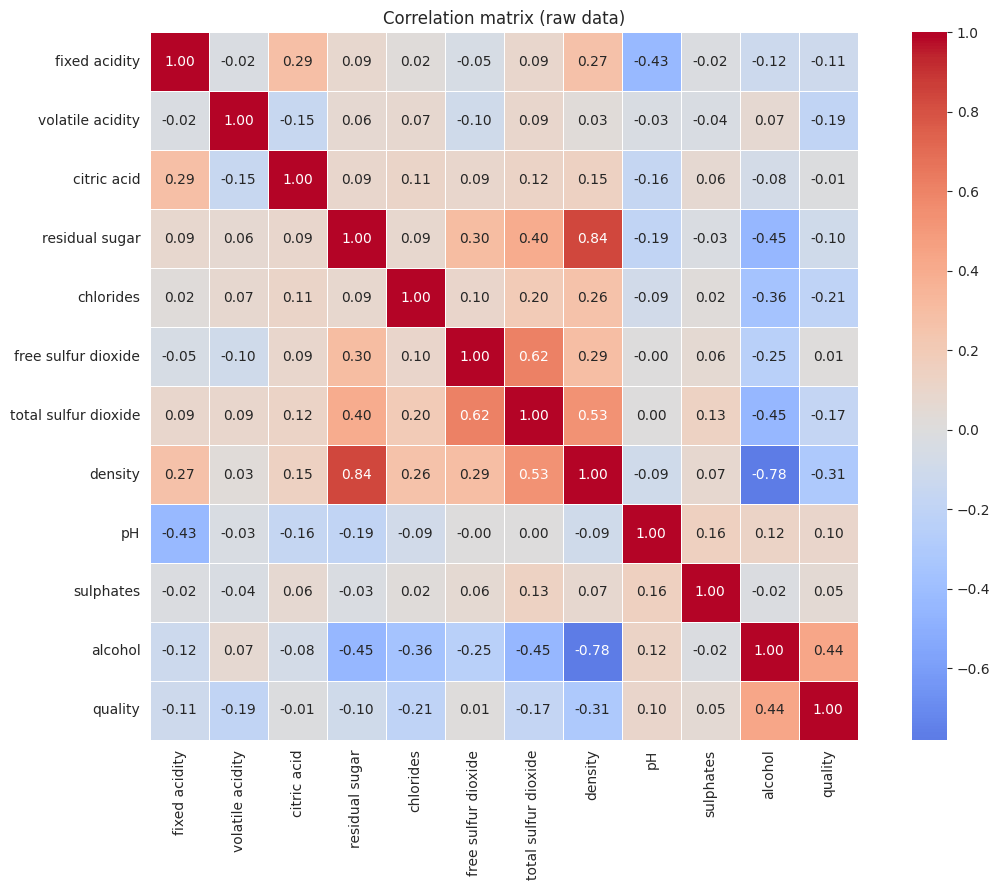

Correlation with target quality (abs sorted):
alcohol                 0.4356
density                -0.3071
chlorides              -0.2099
volatile acidity       -0.1947
total sulfur dioxide   -0.1747
fixed acidity          -0.1137
pH                      0.0994
residual sugar         -0.0976
sulphates               0.0537
citric acid            -0.0092
free sulfur dioxide     0.0082


In [16]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title('Correlation matrix (raw data)')
plt.tight_layout()
plt.savefig('raw_correlation.png', dpi=100, bbox_inches='tight')
plt.show()

print('Correlation with target quality (abs sorted):')
corr_target = corr['quality'].drop('quality')
corr_target = corr_target.sort_values(key=abs, ascending=False)
print(corr_target.round(4).to_string())

## 12. Топ мультиколлинеарных пар

In [17]:
corr_abs = corr.abs()
np.fill_diagonal(corr_abs.values, 0)

pairs = corr_abs.unstack().sort_values(ascending=False)
seen = set()
rows = []
for (a, b), v in pairs.items():
    key = tuple(sorted([a, b]))
    if key in seen:
        continue
    seen.add(key)
    rows.append({'feature_1': a, 'feature_2': b, 'abs_corr': round(v, 4)})
    if len(rows) == 10:
        break

print('Top-10 strongest correlations between features:')
print(pd.DataFrame(rows).to_string(index=False))

Top-10 strongest correlations between features:
           feature_1            feature_2  abs_corr
             density       residual sugar    0.8390
             alcohol              density    0.7801
total sulfur dioxide  free sulfur dioxide    0.6155
total sulfur dioxide              density    0.5299
             alcohol       residual sugar    0.4506
total sulfur dioxide              alcohol    0.4489
             quality              alcohol    0.4356
       fixed acidity                   pH    0.4259
      residual sugar total sulfur dioxide    0.4014
           chlorides              alcohol    0.3602


## 13. Итоговое резюме

In [18]:
n_rows = df.shape[0]
n_cols_total = df.shape[1]
n_features = n_cols_total - 1
n_missing = int(df.isnull().sum().sum())
n_dups = int(df.duplicated().sum())
n_const = len([c for c in df.columns if df[c].nunique() == 1])
n_classes = df['quality'].nunique()
imbalance = round(counts.max() / counts.min(), 2)

skewed = df.skew(numeric_only=True).sort_values(key=abs, ascending=False)
top_skewed = skewed.head(4).round(2).to_dict()

top_corr = corr['quality'].drop('quality').sort_values(key=abs, ascending=False)
top_corr_dict = top_corr.head(4).round(3).to_dict()

print('=' * 70)
print('SUMMARY OF RAW PROFILE')
print('=' * 70)
print('Rows:', n_rows)
print('Columns total:', n_cols_total)
print('Features (without target):', n_features)
print('Missing cells:', n_missing)
print('Duplicated rows:', n_dups)
print('Duplicated share (%):', round(n_dups / n_rows * 100, 2))
print('Constant columns:', n_const)
print('Classes in quality:', n_classes)
print('Class imbalance max/min:', imbalance)
print()
print('Total rule violations:', int(checks_df['violations'].sum()))
print('Checks with violations:', int((checks_df['violations'] > 0).sum()))
print()
print('Top skewed features (abs):')
for k, v in top_skewed.items():
    print('  ' + k + ':', v)
print()
print('Top correlations with quality:')
for k, v in top_corr_dict.items():
    print('  ' + k + ':', v)

SUMMARY OF RAW PROFILE
Rows: 4898
Columns total: 12
Features (without target): 11
Missing cells: 0
Duplicated rows: 937
Duplicated share (%): 19.13
Constant columns: 0
Classes in quality: 7
Class imbalance max/min: 439.6

Total rule violations: 0
Checks with violations: 0

Top skewed features (abs):
  chlorides: 5.02
  volatile acidity: 1.58
  free sulfur dioxide: 1.41
  citric acid: 1.28

Top correlations with quality:
  alcohol: 0.436
  density: -0.307
  chlorides: -0.21
  volatile acidity: -0.195


In [19]:
print('Generated files:')
for f in ['raw_class_bar.png', 'raw_distributions.png',
          'raw_boxplots.png', 'raw_correlation.png']:
    print('  ' + f + ' - ' + str(os.path.exists(f)))

Generated files:
  raw_class_bar.png - True
  raw_distributions.png - True
  raw_boxplots.png - True
  raw_correlation.png - True
